# Parte 3 · Pronóstico de abajo hacia arriba y de arriba hacia abajo

**Autora:** Sofía Isabela Sandoval Vásquez · Grupo 1

**Declaración de uso de IA:** se utilizó Claude (Anthropic) como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por la autora.

In [1]:
import sys, json, os
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datos import cargar_cdnow, resumen_clientes, serie_semanal_repetidas
from bgnbd import esperado_X, esperado_Y

trans = cargar_cdnow("../data/CDNOW_sample.txt")
res = resumen_clientes(trans, "1997-09-30", "1998-06-30")

RUTA_PARAMS = "../resultados/params_cdnow.json"
if os.path.exists(RUTA_PARAMS):
    params = json.load(open(RUTA_PARAMS))
    print("Parámetros estimados en 2.1:", params)
else:
    params = {"r": 0.243, "alpha": 4.414, "a": 0.793, "b": 2.426}
    print("Aún no existe params_cdnow.json; se usan los del artículo:", params)

Aún no existe params_cdnow.json; se usan los del artículo: {'r': 0.243, 'alpha': 4.414, 'a': 0.793, 'b': 2.426}


### Verificación de E[X] y E[Y] contra `lifetimes`

Las fórmulas se programaron a mano con `scipy.special.hyp2f1`. `lifetimes` se usa solo para comprobar que dan lo mismo con los mismos parámetros.

In [2]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
from lifetimes import BetaGeoFitter

bgf = BetaGeoFitter()
bgf.params_ = pd.Series(params)

t_prueba = np.array([1, 5, 13, 26, 39, 78])
ey_propio = esperado_Y(39, res["x"], res["tx"], res["T"], params)
ey_lifetimes = bgf.conditional_expected_number_of_purchases_up_to_time(39, res["x"], res["tx"], res["T"]).values

pd.DataFrame({
    "función": ["E[X(t)], t = 1…78", "E[Y(39) | x, tx, T], 2 357 clientes"],
    "diferencia máxima": [
        np.abs(esperado_X(t_prueba, params) - bgf.expected_number_of_purchases_up_to_time(t_prueba)).max(),
        np.abs(ey_propio - ey_lifetimes).max(),
    ],
})

,función,diferencia máxima
0,"E[X(t)], t = 1…78",0.000000e+00
1,"E[Y(39) | x, tx, T], 2 357 clientes",1.172396e-12


## 3.1 · Bottom-up: curva acumulada de compras repetidas

Cada cliente empezó en una semana distinta, así que al final de la semana *w* el cliente *i* lleva *w − s<sub>i</sub>* semanas en la base (*s<sub>i</sub>* = semana de su primera compra). La curva esperada de la cohorte es la suma de E[X(w − s<sub>i</sub>)] sobre los clientes que ya habían llegado.

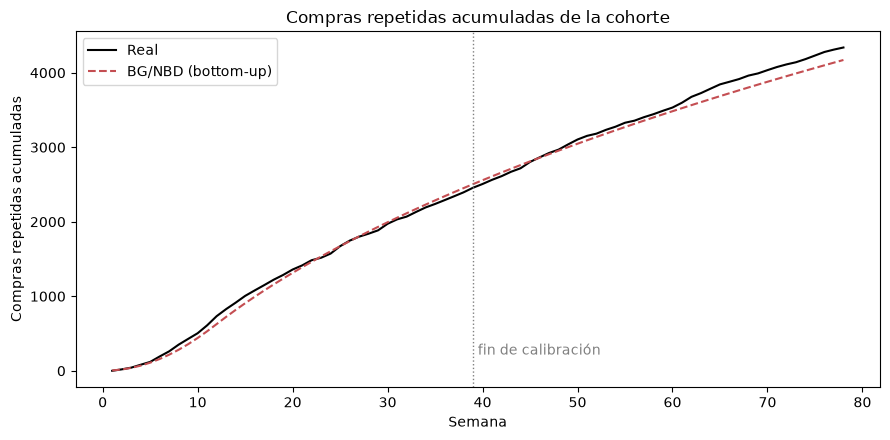

In [3]:
semanas = np.arange(1, 79)
dt = semanas[:, None] - res["semana_primera"].values[None, :]
acum_bgnbd = np.where(dt > 0, esperado_X(np.clip(dt, 0, None), params), 0).sum(axis=1)

real = serie_semanal_repetidas(trans, 78)
acum_real = real.cumsum().values

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(semanas, acum_real, color="black", label="Real")
ax.plot(semanas, acum_bgnbd, color="#C44E52", ls="--", label="BG/NBD (bottom-up)")
ax.axvline(39, color="gray", ls=":", lw=1)
ax.text(39.5, acum_real.max() * 0.05, "fin de calibración", color="gray")
ax.set(title="Compras repetidas acumuladas de la cohorte", xlabel="Semana", ylabel="Compras repetidas acumuladas")
ax.legend()
plt.tight_layout()
plt.savefig("../figs/parte3_bottom_up_acumulado.png", dpi=150)
plt.show()

In [4]:
total_real = real.iloc[39:].sum()
total_bgnbd = acum_bgnbd[77] - acum_bgnbd[38]
print(f"Calibración (sem 1-39): real {acum_real[38]:,.0f} | BG/NBD {acum_bgnbd[38]:,.1f}")
print(f"Holdout (sem 40-78):    real {total_real:,.0f} | BG/NBD {total_bgnbd:,.1f} "
      f"({(total_bgnbd - total_real) / total_real:+.1%})")

Calibración (sem 1-39): real 2,457 | BG/NBD 2,505.1
Holdout (sem 40-78):    real 1,882 | BG/NBD 1,666.3 (-11.5%)


**Respuesta 3.1.** En la calibración, la curva del BG/NBD casi se encima con la real. En el holdout se va quedando abajo: pronostica alrededor de 1 666 compras repetidas contra 1 882 reales, es decir, subestima el total en cerca de 11 %. El modelo capta bien la forma de la curva (crece rápido mientras llega la cohorte y luego se aplana), pero pronostica un poco menos actividad de la que hubo entre octubre de 1997 y junio de 1998.

## 3.2 · Top-down: pronóstico de la serie agregada

Se usa solo la serie semanal de compras repetidas de las semanas 1–39 para pronosticar las semanas 40–78, sin información de los clientes. Métodos:

- **Media histórica:** promedio de las semanas 1–39.
- **Naive:** se repite el valor de la semana 39.
- **Media de las últimas k semanas:** ventanas k = 4 y k = 12.
- **Tendencia lineal:** recta ajustada por mínimos cuadrados desde la semana 1, 13 y 20 hasta la 39. Los valores negativos se truncan a 0, porque no puede haber compras negativas.

In [5]:
y = real.iloc[:39].values.astype(float)
h = np.arange(40, 79)

def tendencia(desde):
    xs = np.arange(desde, 40)
    coef = np.polyfit(xs, y[desde - 1:], 1)
    return np.clip(np.polyval(coef, h), 0, None)

pronosticos = {
    "BG/NBD (bottom-up)": np.diff(acum_bgnbd)[38:],
    "Media histórica": np.full(39, y.mean()),
    "Naive": np.full(39, y[-1]),
    "Media últimas 4 sem": np.full(39, y[-4:].mean()),
    "Media últimas 12 sem": np.full(39, y[-12:].mean()),
    "Tendencia desde sem 1": tendencia(1),
    "Tendencia desde sem 13": tendencia(13),
    "Tendencia desde sem 20": tendencia(20),
}

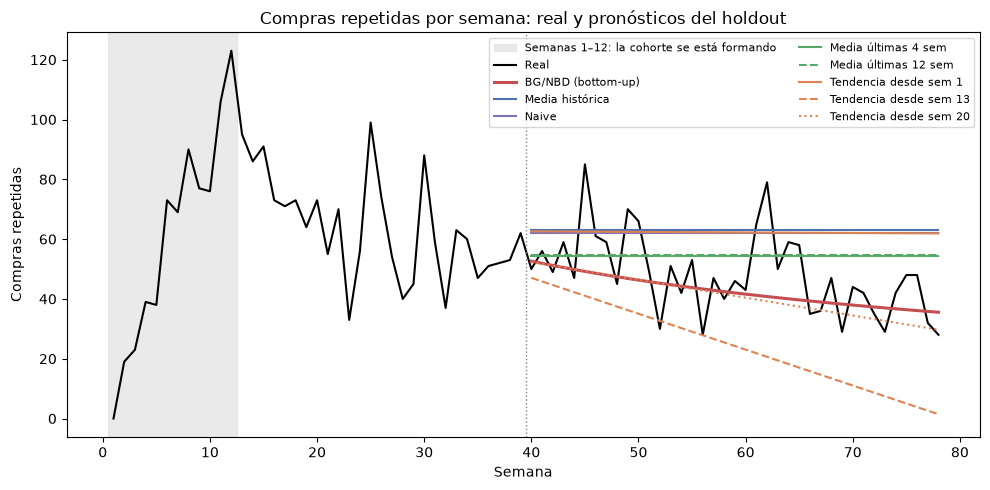

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(0.5, 12.5, color="#DDDDDD", alpha=0.6, label="Semanas 1–12: la cohorte se está formando")
ax.plot(semanas, real.values, color="black", lw=1.5, label="Real")
estilos = {
    "BG/NBD (bottom-up)": dict(color="#C44E52", lw=2.2),
    "Media histórica": dict(color="#4C72B0"),
    "Naive": dict(color="#8172B2"),
    "Media últimas 4 sem": dict(color="#55A868"),
    "Media últimas 12 sem": dict(color="#55A868", ls="--"),
    "Tendencia desde sem 1": dict(color="#DD8452"),
    "Tendencia desde sem 13": dict(color="#DD8452", ls="--"),
    "Tendencia desde sem 20": dict(color="#DD8452", ls=":"),
}
for nombre, pron in pronosticos.items():
    ax.plot(h, pron, label=nombre, **estilos[nombre])
ax.axvline(39.5, color="gray", ls=":", lw=1)
ax.set(title="Compras repetidas por semana: real y pronósticos del holdout", xlabel="Semana", ylabel="Compras repetidas")
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.tight_layout()
plt.savefig("../figs/parte3_top_down_semanal.png", dpi=150)
plt.show()

## 3.3 · Comparación de métodos

In [7]:
real_h = real.iloc[39:].values
tabla = pd.DataFrame({
    "Total holdout pronosticado": {k: v.sum() for k, v in pronosticos.items()},
    "Error porcentual (%)": {k: (v.sum() - real_h.sum()) / real_h.sum() * 100 for k, v in pronosticos.items()},
    "MAE semanal": {k: np.abs(v - real_h).mean() for k, v in pronosticos.items()},
}).sort_values("MAE semanal")
print(f"Total real del holdout: {real_h.sum():,}")
tabla.round(1)

Total real del holdout: 1,882


,Total holdout pronosticado,Error porcentual (%),MAE semanal
BG/NBD (bottom-up),1666.3,-11.5,9.8
Tendencia desde sem 20,1599.2,-15.0,10.2
Media últimas 4 sem,2125.5,12.9,12.3
Media últimas 12 sem,2135.2,13.5,12.4
Naive,2418.0,28.5,16.6
Tendencia desde sem 1,2428.4,29.0,16.7
Media histórica,2457.0,30.6,17.3
Tendencia desde sem 13,945.5,-49.8,24.1


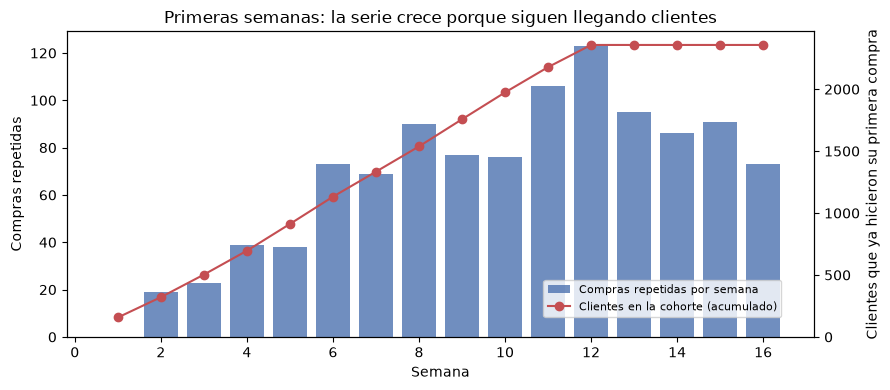

In [8]:
llegada = res.groupby(np.floor(res["semana_primera"]).astype(int) + 1).size().reindex(semanas[:16], fill_value=0).cumsum()

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.bar(semanas[:16], real.values[:16], color="#4C72B0", alpha=0.8, label="Compras repetidas por semana")
ax1.set(xlabel="Semana", ylabel="Compras repetidas")
ax2 = ax1.twinx()
ax2.plot(semanas[:16], llegada.values, color="#C44E52", marker="o", label="Clientes en la cohorte (acumulado)")
ax2.set_ylabel("Clientes que ya hicieron su primera compra")
ax2.set_ylim(0, None)
ax1.set_title("Primeras semanas: la serie crece porque siguen llegando clientes")
fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.18), fontsize=8)
plt.tight_layout()
plt.savefig("../figs/parte3_primeras_semanas.png", dpi=150)
plt.show()

**Respuesta 3.3.**

- **¿Quién gana?** El BG/NBD tiene el menor MAE semanal (≈ 9.8) y el menor error en el total (≈ −11.5 %). El mejor top-down en MAE es la tendencia desde la semana 20 (≈ 10.2), pero su error en el total es mayor (≈ −15 %).
- **Sensibilidad a la ventana:** la tendencia lineal es muy sensible. Ajustada desde la semana 1 sobreestima el holdout en ≈ +29 %; desde la 13 lo subestima en ≈ −50 %, y desde la 20, en ≈ −15 %. La media móvil es más estable: con 4 o 12 semanas el error se queda alrededor de +13 %. La media histórica y el naive sobreestiman ≈ 30 %.
- **Las primeras 12 semanas:** la cohorte se está formando. Los clientes hicieron su primera compra entre el 1 de enero y finales de marzo de 1997, así que en esas semanas la serie sube porque **entran clientes nuevos**, no porque cada cliente compre más. Después de la semana 12 ya no entra nadie y la serie baja conforme los clientes se van "muriendo". Un método top-down solo ve el total. No sabe que la cohorte está cerrada, así que confunde el crecimiento por llegada de clientes con una tendencia (la tendencia desde la semana 1 sigue subiendo), y la media histórica y el naive arrastran ese nivel. El BG/NBD sí conoce cuándo llegó cada cliente.

## 3.4 · Pronóstico por cliente según su frecuencia en calibración

In [9]:
res["E_Y39"] = esperado_Y(39, res["x"], res["tx"], res["T"], params)
res["grupo_x"] = np.minimum(res["x"], 7)

por_grupo = res.groupby("grupo_x").agg(
    clientes=("x", "size"),
    pronostico_BGNBD=("E_Y39", "mean"),
    real_x_star=("x_star", "mean"),
)
por_grupo["error_relativo_%"] = (por_grupo["pronostico_BGNBD"] - por_grupo["real_x_star"]) / por_grupo["real_x_star"] * 100
por_grupo.index = [str(i) if i < 7 else "7+" for i in por_grupo.index]
por_grupo.index.name = "x en calibración"
por_grupo.round(3)

,clientes,pronostico_BGNBD,real_x_star,error_relativo_%
x en calibración,,,,
0,1411,0.225,0.237,-4.757
1,439,0.523,0.697,-24.943
2,214,1.044,1.393,-25.016
3,100,1.520,1.560,-2.545
4,62,2.164,2.532,-14.548
5,38,2.654,2.947,-9.959
6,29,3.504,3.862,-9.272
7+,64,6.157,6.359,-3.181


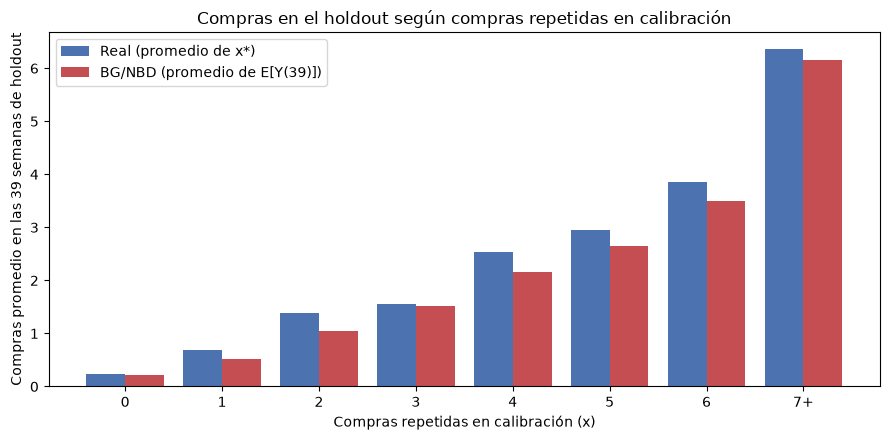

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
pos = np.arange(len(por_grupo))
ax.bar(pos - 0.2, por_grupo["real_x_star"], width=0.4, color="#4C72B0", label="Real (promedio de x*)")
ax.bar(pos + 0.2, por_grupo["pronostico_BGNBD"], width=0.4, color="#C44E52", label="BG/NBD (promedio de E[Y(39)])")
ax.set_xticks(pos, por_grupo.index)
ax.set(title="Compras en el holdout según compras repetidas en calibración",
       xlabel="Compras repetidas en calibración (x)", ylabel="Compras promedio en las 39 semanas de holdout")
ax.legend()
plt.tight_layout()
plt.savefig("../figs/parte3_por_cliente.png", dpi=150)
plt.show()

**Respuesta 3.4.** El modelo ordena bien a los clientes: el pronóstico promedio crece con x, igual que lo real. En casi todos los grupos subestima un poco. Las mayores diferencias relativas están en los grupos **x = 1 y x = 2** (≈ −25 %): son clientes que volvieron a comprar pocas veces y a los que el modelo les da más probabilidad de haberse ido de la que realmente tenían. Para x = 0, x = 3 y 7+, el pronóstico queda muy cerca del real.

**¿Lo puede hacer un pronóstico top-down?** No. Un método top-down solo produce un número por semana para toda la cohorte; no tiene información de quién compró cuánto, así que no puede decir cuánto va a comprar cada cliente ni cada grupo. Para eso hace falta un modelo a nivel cliente, como el BG/NBD.